# 5. Embeddings vectoriales para lenguaje hispano

Este notebook toma `output/corpus_anfibia_limpio.csv` y construye una representación vectorial densa por documento en lugar de una matriz bag of words.

A diferencia del notebook 3, acá cada documento queda representado por un embedding semántico generado con un modelo de libre acceso entrenado para español: `dccuchile/bert-base-spanish-wwm-cased` (BETO). Los campos `tagline`, `autor_names`, `post_date`, `category` y `text_type` se preservan como atributos acompañantes, no como entrada adicional al modelo.

## 1. Configuración

In [ ]:
from pathlib import Path
import json
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Rutas estándar del proyecto usando tu CSV
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROCESSED_DATA_PATH / "embeddings_hispanos"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DATA_PATH / "corpus_anfibia_limpio.csv"
assert DATA_PATH.exists(), f"Falta archivo de entrada: {DATA_PATH.name}"

MODEL_NAME = "dccuchile/bert-base-spanish-wwm-cased"
MAX_LENGTH = 512
STRIDE = 128
BATCH_SIZE = 8
MAX_DOCUMENTS = 25
RANDOM_STATE = 42

DATA_PATH

WindowsPath('C:/Trabajos/anfibia/output/corpus_anfibia_limpio.csv')

### Dependencias opcionales para embeddings

Si esta celda indica que falta `transformers`, `torch` o una versión reciente de `Pillow`, instalá los paquetes una vez y reiniciá el kernel:

```bash
python3 -m pip install -U transformers torch Pillow
```

In [3]:
try:
    import PIL.Image
    import torch
    from transformers import AutoModel, AutoTokenizer
    if not hasattr(PIL.Image, "Resampling"):
        raise ImportError("Pillow debe actualizarse: python3 -m pip install -U Pillow")
    TRANSFORMERS_AVAILABLE = True
except (ModuleNotFoundError, ImportError) as exc:
    TRANSFORMERS_AVAILABLE = False
    TRANSFORMERS_IMPORT_ERROR = exc
    torch = None
    AutoModel = None
    AutoTokenizer = None

TRANSFORMERS_AVAILABLE, None if TRANSFORMERS_AVAILABLE else str(TRANSFORMERS_IMPORT_ERROR)

c:\Trabajos\anfibia\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(True, None)

## 2. Carga del corpus

In [4]:
TEXT_COLUMN = "document_text_final"
ATTRIBUTE_COLUMNS = ["tagline", "autor_names", "post_date", "category", "text_type"]
ID_COLUMNS = ["ID", "source_url", "title_text"]
USE_COLUMNS = ID_COLUMNS + ATTRIBUTE_COLUMNS + [TEXT_COLUMN]

df = pd.read_csv(DATA_PATH, usecols=USE_COLUMNS,nrows=MAX_DOCUMENTS)

df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna("").astype(str)
for col in ATTRIBUTE_COLUMNS:
    df[col] = df[col].fillna("").astype(str).str.strip()

df = df[df[TEXT_COLUMN].str.strip().ne("")].copy()
df = df.reset_index(drop=True)
df.insert(0, "doc_id", df.index)

df.shape

(25, 10)

In [5]:
display(df[ID_COLUMNS + ATTRIBUTE_COLUMNS].head())
display(df["category"].value_counts().head(20).to_frame("documents"))

,ID,source_url,title_text,tagline,autor_names,post_date,category,text_type
0,15668,https://www.revistaanfibia.com/la-china-invisi...,La China invisible,Feria La Salada,Sebastián Hacher; Ariel Wilkis,2012-05-14 13:43:22,Política y Economía,Crónica
1,15706,https://www.revistaanfibia.com/grobocopatel-el...,El rico que se cree Steve Jobs,Gustavo Grobocopatel,Graciela Mochkofsky; Alexandre Roig,2012-05-24 13:36:12,Política y Economía,Crónica
2,15743,https://www.revistaanfibia.com/la-vaca-sagrada/,La vaca sagrada,,Josefina Licitra,2012-06-05 14:52:58,Tecnologías,
3,15695,https://www.revistaanfibia.com/los-arruinados-...,Los arruinados del Paraná,Adictos al juego,Gisele Sousa Dias,2012-06-14 10:16:11,Culturas,
4,15687,https://www.revistaanfibia.com/de-chile-tacna-...,De Chile a Tacna: una historia de carniceros y...,,Jorge Turpo Rivas,2012-06-25 14:52:05,Culturas,Crónica


,documents
category,
Política y Economía,12
Culturas,8
Políticas de géneros,2
Tecnologías,1
Amor y sexo,1
Otras,1


## 3. Categorías normalizadas

In [6]:
def split_categories(value):
    parts = re.split(r"[;,]", str(value))
    return [part.strip() for part in parts if part.strip()]

category_rows = []
for doc_id, value in zip(df["doc_id"], df["category"]):
    categories = split_categories(value)
    if not categories:
        categories = ["Sin categoria"]
    for category in categories:
        category_rows.append({"doc_id": doc_id, "category_normalized": category})

categories_df = pd.DataFrame(category_rows)
category_counts = categories_df["category_normalized"].value_counts().rename_axis("category").reset_index(name="documents")

display(category_counts)

,category,documents
0,Política y Economía,12
1,Culturas,8
2,Políticas de géneros,2
3,Tecnologías,1
4,Amor y sexo,1
5,Otras,1


## 4. Modelo de embeddings

BETO devuelve embeddings por token. Para obtener un vector por documento, este notebook divide textos largos en ventanas de hasta `MAX_LENGTH` tokens, calcula un promedio enmascarado por ventana y luego promedia las ventanas ponderando por cantidad de tokens válidos.

Este enfoque evita descartar todo lo que queda después de los primeros 512 tokens, que es el límite típico de los modelos BERT.

In [7]:
if not TRANSFORMERS_AVAILABLE:
    raise ModuleNotFoundError("Faltan dependencias para embeddings. Instalá con: python3 -m pip install -U transformers torch Pillow")

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

device

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 24624.58it/s]
[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

'cpu'

In [8]:
def add_bert_special_tokens(token_ids, tokenizer):
    if tokenizer.cls_token_id is None or tokenizer.sep_token_id is None:
        raise ValueError("El tokenizer no expone cls_token_id/sep_token_id para construir ventanas BERT.")
    return [tokenizer.cls_token_id] + list(token_ids) + [tokenizer.sep_token_id]

def make_token_windows(text, tokenizer, max_length=512, stride=128):
    encoded = tokenizer(
        str(text),
        add_special_tokens=False,
        truncation=False,
        return_attention_mask=False,
        return_token_type_ids=False,
        verbose=False,
    )["input_ids"]
    if not encoded:
        encoded = tokenizer(" ", add_special_tokens=False, verbose=False)["input_ids"]

    content_window = max_length - tokenizer.num_special_tokens_to_add(pair=False)
    step = max(1, content_window - stride)
    windows = []
    for start in range(0, len(encoded), step):
        window = encoded[start:start + content_window]
        if not window:
            continue
        windows.append(add_bert_special_tokens(window, tokenizer))
        if start + content_window >= len(encoded):
            break
    return windows

def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    masked_sum = (last_hidden_state * mask).sum(dim=1)
    token_counts = mask.sum(dim=1).clamp(min=1e-9)
    return masked_sum / token_counts

def embed_documents(texts, tokenizer, model, device, max_length=512, stride=128, batch_size=8):
    document_embeddings = []
    document_window_counts = []

    for doc_idx, text in enumerate(texts, start=1):
        windows = make_token_windows(text, tokenizer, max_length=max_length, stride=stride)
        chunk_vectors = []
        chunk_weights = []

        for start in range(0, len(windows), batch_size):
            batch_windows = windows[start:start + batch_size]
            batch = tokenizer.pad(
                {"input_ids": batch_windows},
                padding=True,
                return_attention_mask=True,
                return_tensors="pt",
            )
            batch = {key: value.to(device) for key, value in batch.items()}
            with torch.no_grad():
                outputs = model(**batch)
            pooled = mean_pool(outputs.last_hidden_state, batch["attention_mask"])
            weights = batch["attention_mask"].sum(dim=1).detach().cpu().numpy()
            chunk_vectors.append(pooled.detach().cpu().numpy())
            chunk_weights.append(weights)

        chunk_vectors = np.vstack(chunk_vectors)
        chunk_weights = np.concatenate(chunk_weights)
        document_embedding = np.average(chunk_vectors, axis=0, weights=chunk_weights)
        document_embeddings.append(document_embedding)
        document_window_counts.append(len(windows))

        if doc_idx % 25 == 0 or doc_idx == len(texts):
            print(f"Documentos embebidos: {doc_idx}/{len(texts)}")

    return np.vstack(document_embeddings).astype("float32"), document_window_counts

## 5. Generación de embeddings

In [9]:
embeddings, window_counts = embed_documents(
    df[TEXT_COLUMN].tolist(),
    tokenizer=tokenizer,
    model=model,
    device=device,
    max_length=MAX_LENGTH,
    stride=STRIDE,
    batch_size=BATCH_SIZE,
)

embeddings.shape

Documentos embebidos: 25/25


(25, 768)

## 6. Guardado de matriz y atributos

In [11]:
attributes = df[["doc_id"] + ID_COLUMNS + ATTRIBUTE_COLUMNS].copy()
attributes["category_list"] = df["category"].map(split_categories)
attributes["word_count_raw_text"] = df[TEXT_COLUMN].str.split().map(len)
attributes["embedding_window_count"] = window_counts

document_index = attributes[["doc_id", "ID", "source_url", "title_text"]].copy()

np.save(OUTPUT_DIR / "embedding_document_matrix.npy", embeddings)
attributes.to_csv(OUTPUT_DIR / "embedding_document_attributes.csv", index=False)
document_index.to_csv(OUTPUT_DIR / "embedding_document_index.csv", index=False)

with open(OUTPUT_DIR / "embedding_model_config.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "source_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
            "text_column": TEXT_COLUMN,
            "attribute_columns": ATTRIBUTE_COLUMNS,
            "id_columns": ID_COLUMNS,
            "model_name": MODEL_NAME,
            "max_length": MAX_LENGTH,
            "stride": STRIDE,
            "batch_size": BATCH_SIZE,
            "device": device,
            "n_documents": int(embeddings.shape[0]),
            "embedding_dimensions": int(embeddings.shape[1]),
            "matrix_file": "embedding_document_matrix.npy",
            "attributes_file": "embedding_document_attributes.csv",
            "document_index_file": "embedding_document_index.csv",
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

{
    "matrix": str((OUTPUT_DIR / "embedding_document_matrix.npy").relative_to(PROJECT_ROOT)),
    "attributes": str((OUTPUT_DIR / "embedding_document_attributes.csv").relative_to(PROJECT_ROOT)),
    "document_index": str((OUTPUT_DIR / "embedding_document_index.csv").relative_to(PROJECT_ROOT)),
    "config": str((OUTPUT_DIR / "embedding_model_config.json").relative_to(PROJECT_ROOT)),
}

{'matrix': 'output\\embeddings_hispanos\\embedding_document_matrix.npy',
 'attributes': 'output\\embeddings_hispanos\\embedding_document_attributes.csv',
 'document_index': 'output\\embeddings_hispanos\\embedding_document_index.csv',
 'config': 'output\\embeddings_hispanos\\embedding_model_config.json'}

## 7. Exploración rápida: documentos cercanos

In [12]:
neighbors = NearestNeighbors(n_neighbors=6, metric="cosine")
neighbors.fit(embeddings)

QUERY_DOC_ID = 0
distances, indices = neighbors.kneighbors(embeddings[[QUERY_DOC_ID]])

similar_docs = attributes.iloc[indices[0]].copy()
similar_docs.insert(1, "cosine_similarity", 1 - distances[0])
display(similar_docs[["doc_id", "cosine_similarity", "title_text", "category", "post_date"]])

,doc_id,cosine_similarity,title_text,category,post_date
0,0,1.000000,La China invisible,Política y Economía,2012-05-14 13:43:22
3,3,0.993377,Los arruinados del Paraná,Culturas,2012-06-14 10:16:11
16,16,0.991354,La reforma agraria de las mujeres guaraníes,Políticas de géneros,2012-10-01 17:32:04
18,18,0.989953,Jóvenes de San Judas: el México desesperado,Culturas,2012-10-10 14:04:09
24,24,0.989917,Limpiar la muerte,Culturas,2012-12-05 12:36:41
13,13,0.988343,La derecha respira,Política y Economía,2012-09-11 09:01:39


## 8. Visualización 2D de embeddings

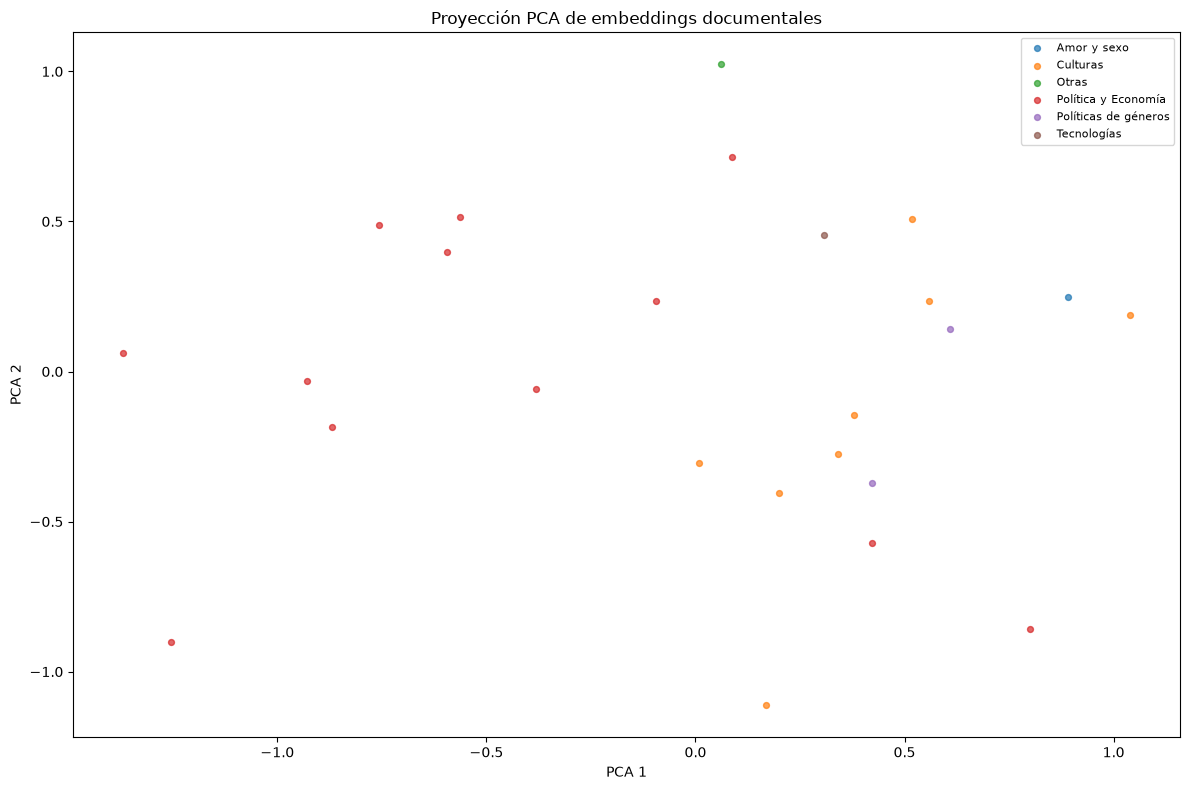

In [15]:
sample_size = min(1200, len(attributes))
sample = attributes.sample(sample_size, random_state=RANDOM_STATE)
sample_embeddings = embeddings[sample["doc_id"].to_numpy()]

pca = PCA(n_components=2, random_state=RANDOM_STATE)
points = pca.fit_transform(sample_embeddings)

plot_df = sample.copy()
plot_df["x"] = points[:, 0]
plot_df["y"] = points[:, 1]
plot_df["category_primary"] = plot_df["category"].map(lambda value: split_categories(value)[0] if split_categories(value) else "Sin categoria")

top_categories = plot_df["category_primary"].value_counts().head(10).index
plot_df["category_plot"] = np.where(plot_df["category_primary"].isin(top_categories), plot_df["category_primary"], "Otras")

fig, ax = plt.subplots(figsize=(12, 8))
for category, group in plot_df.groupby("category_plot"):
    ax.scatter(group["x"], group["y"], s=18, alpha=0.7, label=category)

ax.set_title("Proyección PCA de embeddings documentales")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

## 9. Cómo recargar la matriz después

In [16]:
loaded_embeddings = np.load(OUTPUT_DIR / "embedding_document_matrix.npy")
loaded_attributes = pd.read_csv(OUTPUT_DIR / "embedding_document_attributes.csv")

with open(OUTPUT_DIR / "embedding_model_config.json", encoding="utf-8") as f:
    embedding_config = json.load(f)

loaded_embeddings.shape, loaded_attributes.shape, embedding_config["model_name"]

((25, 768), (25, 12), 'dccuchile/bert-base-spanish-wwm-cased')